# Weber BLL — Cumulative Regret Evaluation

## What is Weber BLL?

**Weber et al. (2018), "Optimizing over a Bayesian Last Layer"** proposes a method for training neural network feature extractors in a bandit setting. The architecture has two components:

1. **Feature extractor** $f_\theta(x)$: maps context $x$ to features $h$ (linear or MLP)
2. **Bayesian linear last layer**: per-arm regression $z_n \sim \mathcal{N}(\mu_n, \Sigma_n)$ on top of features, with closed-form posterior updates

The key idea: when retraining the feature extractor, instead of optimizing the log-likelihood at the posterior **mean** $\hat{\theta}$, Weber marginalizes over **all** values of the last layer, weighted by the posterior.

### Closed-form marginalized gradient (Gaussian case)

For arm $n$ with posterior $z_n \sim \mathcal{N}(\mu_n, \Sigma_n)$, features $h$, and target $y_n$:

$$\nabla_h \mathbb{E}_{z_n}[\log p(y_n \mid z_n, h)] = -\frac{1}{\sigma^2}\left[(\mu_n^\top h - y_n)\mu_n + \Sigma_n h\right]$$

Two terms:
- **MSE gradient**: $(\text{pred}_n - y_n) \cdot \mu_n$ — standard prediction error signal
- **Uncertainty correction**: $\Sigma_n h$ — the Weber contribution! Pushes features toward directions where the posterior is uncertain

### Algorithm structure (strictly phased)

- **Online phase** (features frozen): Update Bayesian posterior, use UCB for exploration
- **Offline phase** (every `phase_length` rounds): Retrain features with marginalized LL + diagonal Fisher regularization, then replay all buffered data to rebuild posteriors

### How it differs from BayesianSPO

| | BayesianSPO | Weber BLL |
|---|---|---|
| **Loss** | SPO+ (decision-focused) | Gaussian log-likelihood |
| **Feature updates** | Every round | Phased (batch retraining) |
| **Regularization** | None | Diagonal Fisher (prevents catastrophic forgetting) |
| **Marginalization** | Point estimate (posterior mean) | Closed-form over full posterior |

## Experiment setup

Settings matched to `FINAL_evaluation.ipynb` (loaded from `experiment.yaml`):

| Setting | Value |
|---|---|
| **lr** | 0.001 |
| **hidden_dim** | 16 |
| **lambda_reg** | 1.0 |
| **beta** | 1.0 |
| **n_rounds** | 1000 |
| **seeds** | 10 seeds (0–9) |
| **feedback** | semi-bandit |
| **episode isolation** | pre-generated (all agents see identical data) |

Agents compared:
- **WeberBLL**: Faithful Weber implementation (log-likelihood, phased, Fisher reg)
- **BayesianSPO**: Decision-focused features (SPO+ loss, per-round updates, mask_grad=True)
- **BayesianMSE**: Prediction-focused features (MSE loss, per-round updates)
- **LinUCB**: Linear UCB baseline (no feature learning)

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import yaml
import time

from src.envs import create_env
from src.agents.base import pregenerate_episode, run_agent_on_episode
from src.agents.shared_context import (
    BayesianSPOAgent, BayesianMSEAgent, LinUCBAgent,
)
from src.agents.shared_context.weber_bll import WeberBLLAgent

In [2]:
# ══════════════════════════════════════════════════════════════
# Settings — loaded from experiment.yaml (matching FINAL_evaluation.ipynb)
# ══════════════════════════════════════════════════════════════

with open('../experiments/configs/experiment.yaml') as f:
    config = yaml.safe_load(f)

defaults = config['agent_defaults']
lr = defaults['lr']
lambda_reg = defaults['lambda_reg']
beta = defaults['beta']

DATASETS = {
    'knapsack_32': dict(hidden_dim=defaults['hidden_dim_small']),
    'shortest_path_8x8': dict(hidden_dim=defaults['hidden_dim_small']),
}

N_ROUNDS = 2000
N_SEEDS = 5
SEEDS = list(range(N_SEEDS))

# ══════════════════════════════════════════════════════════════
# Run — pre-generated episodes for fair comparison
# ══════════════════════════════════════════════════════════════

all_trajectories = {}

for ds_name, ds_cfg in DATASETS.items():
    dataset_config = config['datasets'][ds_name].copy()
    dataset_config.pop('env_type', None)
    dataset_config.pop('n_rounds', None)

    hidden_dim = ds_cfg['hidden_dim']

    # Detect minimize from env
    test_env = create_env(ds_name, seed=0, **dataset_config)
    minimize = getattr(test_env, 'minimize', False)
    bayes_beta = -beta if minimize else beta

    print(f'\n{"="*60}')
    print(f'{ds_name.upper()}')
    print(f'  config: {dataset_config}')
    print(f'  hp:  lr={lr}, hidden_dim={hidden_dim}, '
          f'lambda_reg={lambda_reg}, beta={beta}')
    print(f'  n_rounds={N_ROUNDS}, seeds={N_SEEDS}, minimize={minimize}')
    print(f'{"="*60}')

    for seed in SEEDS:
        # Pre-generate episode: all agents see identical data
        env = create_env(ds_name, seed=seed, **dataset_config)
        episode = pregenerate_episode(env, N_ROUNDS)

        # Create agents from a fresh env instance
        env_a = create_env(ds_name, seed=seed, **dataset_config)
        solver = env_a.solve

        common = dict(
            context_dim=env_a.context_dim, n_arms=env_a.n_arms,
            weights=env_a.weights, capacity=env_a.capacity,
        )

        agents = {
            'LinUCB': LinUCBAgent(
                **common, alpha=beta, lambda_reg=lambda_reg,
                minimize=minimize, solver=solver,
            ),
            'BayesianMSE': BayesianMSEAgent(
                **common, hidden_dim=hidden_dim, beta=bayes_beta,
                lambda_reg=lambda_reg, decay_rounds=N_ROUNDS,
                solver=solver, seed=seed,
            ),
            'BayesianSPO': BayesianSPOAgent(
                **common, hidden_dim=hidden_dim, beta=bayes_beta,
                decay_rounds=N_ROUNDS, lambda_reg=lambda_reg,
                minimize=minimize, solver=solver, seed=seed,
                mask_grad=True,
            ),
            'WeberBLL': WeberBLLAgent(
                **common, hidden_dim=hidden_dim, beta=bayes_beta,
                decay_rounds=N_ROUNDS, lambda_reg=lambda_reg,
                lr=lr, minimize=minimize, solver=solver, seed=seed,
                mask_grad=True,
            ),
        }

        print(f'\n  seed={seed}:', end='')
        for agent_name, agent in agents.items():
            t0 = time.perf_counter()
            result = run_agent_on_episode(
                agent, episode, N_ROUNDS,
                lr=lr, full_feedback=False,
            )
            dt = time.perf_counter() - t0

            all_trajectories[(agent_name, ds_name, seed)] = {
                'cumulative_regret': result['cumulative_regret'],
                'regrets': result['regrets'],
            }
            print(f'  {agent_name}={result["final_regret"]:.0f}({dt:.1f}s)', end='')
        print()

print('\nDone!')


KNAPSACK_32
  config: {'n_items': 32, 'context_dim': 5, 'capacity': 20.0, 'noise_width': 0.25}
  hp:  lr=0.001, hidden_dim=16, lambda_reg=1.0, beta=1.0
  n_rounds=2000, seeds=5, minimize=False

  seed=0:  LinUCB=10507(9.0s)  BayesianMSE=9314(12.0s)  BayesianSPO=9327(18.0s)  WeberBLL=8001(343.7s)

  seed=1:  LinUCB=8057(3.2s)  BayesianMSE=7810(5.8s)  BayesianSPO=7744(8.9s)  WeberBLL=6302(349.8s)

  seed=2:  LinUCB=11363(3.0s)  BayesianMSE=8758(5.7s)  BayesianSPO=8408(9.0s)  WeberBLL=6193(328.3s)

  seed=3:  LinUCB=9564(2.8s)  BayesianMSE=9773(6.8s)  BayesianSPO=10124(14.1s)  WeberBLL=8215(361.0s)

  seed=4:  LinUCB=8046(4.1s)  BayesianMSE=8787(8.6s)  BayesianSPO=8998(15.5s)  WeberBLL=8388(414.3s)

SHORTEST_PATH_8X8
  config: {'grid_size': 8, 'context_dim': 5, 'noise_width': 0.25}
  hp:  lr=0.001, hidden_dim=16, lambda_reg=1.0, beta=1.0
  n_rounds=2000, seeds=5, minimize=True

  seed=0:  LinUCB=6591(1.5s)  BayesianMSE=3553(3.9s)  BayesianSPO=3169(4.0s)  WeberBLL=3281(408.7s)

  seed=1: 

## Results

In [3]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({'font.size': 12})

AGENT_NAMES = ['LinUCB', 'BayesianMSE', 'BayesianSPO', 'WeberBLL']
COLORS = {
    'LinUCB':      '#7f7f7f',
    'BayesianMSE': '#1f77b4',
    'BayesianSPO': '#d62728',
    'WeberBLL':    '#2ca02c',
}
LABELS = {
    'LinUCB':      'LinUCB',
    'BayesianMSE': 'BayesianMSE',
    'BayesianSPO': 'BayesianSPO',
    'WeberBLL':    'Weber BLL',
}
DS_NAMES = list(DATASETS.keys())

def get_trajectories(ds_name, agent_name, metric='cumulative_regret'):
    """Collect trajectories across seeds for one agent on one dataset."""
    trajs = []
    for s in SEEDS:
        key = (agent_name, ds_name, s)
        if key in all_trajectories:
            trajs.append(all_trajectories[key][metric])
    return np.array(trajs) if trajs else np.array([])

### Cumulative Regret Over Time

The main comparison: how total regret accumulates as agents learn. Lower is better. Shaded regions show ±1 std across seeds.

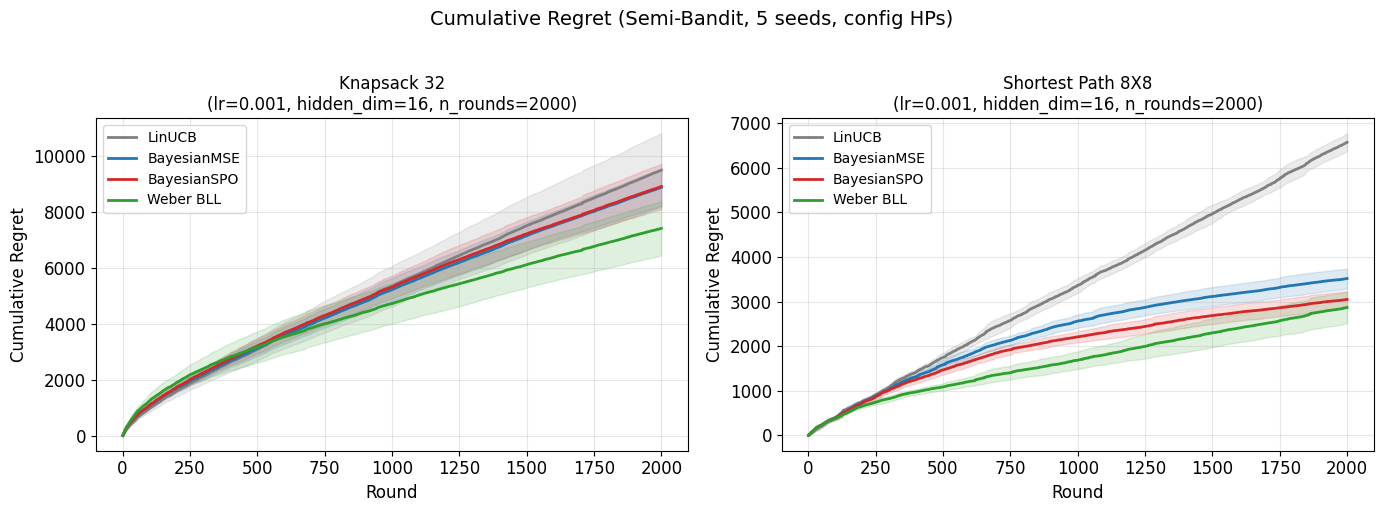

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ds_name in zip(axes, DS_NAMES):
    rounds = np.arange(1, N_ROUNDS + 1)
    
    for agent_name in AGENT_NAMES:
        trajs = get_trajectories(ds_name, agent_name)
        if len(trajs) == 0:
            continue
        mean = trajs.mean(axis=0)
        std = trajs.std(axis=0)
        
        ax.plot(rounds, mean, color=COLORS[agent_name], 
                label=LABELS[agent_name], linewidth=2)
        ax.fill_between(rounds, mean - std, mean + std,
                        color=COLORS[agent_name], alpha=0.15)
    
    title = ds_name.replace('_', ' ').title()
    ax.set_title(f'{title}\n(lr={lr}, hidden_dim={DATASETS[ds_name]["hidden_dim"]}, '
                 f'n_rounds={N_ROUNDS})', fontsize=12)
    ax.set_xlabel('Round')
    ax.set_ylabel('Cumulative Regret')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)

fig.suptitle(f'Cumulative Regret (Semi-Bandit, {N_SEEDS} seeds, config HPs)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Instantaneous Regret (Smoothed)

Per-round regret smoothed with a rolling window. Shows how quickly each agent's per-round performance improves. Decreasing = agent is learning.

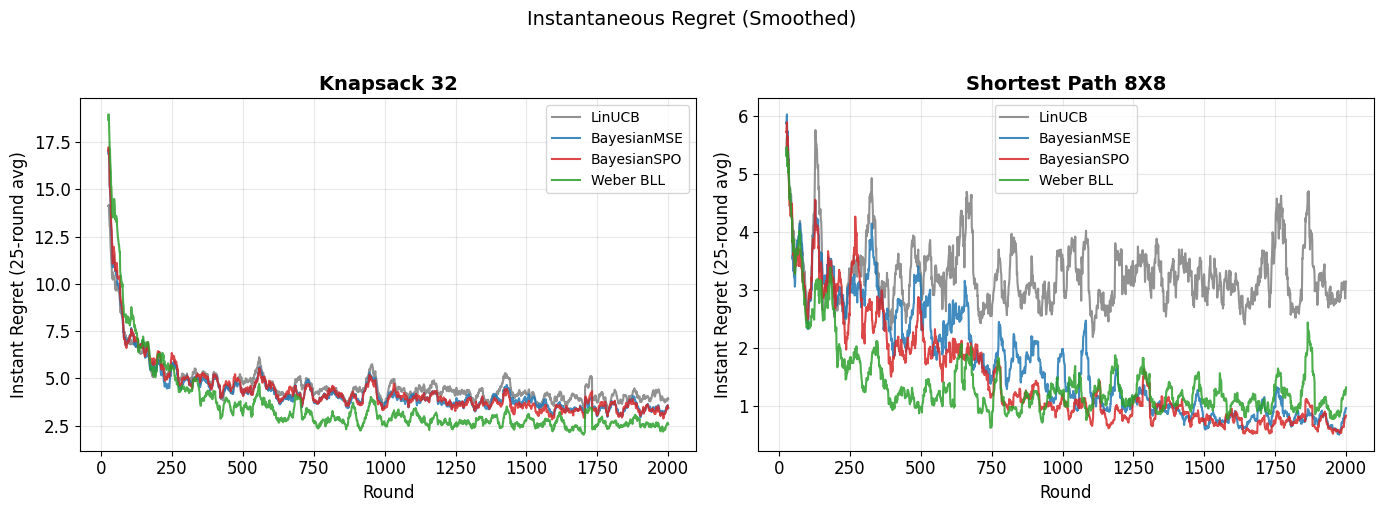

In [5]:
WINDOW = 25

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ds_name in zip(axes, DS_NAMES):
    for agent_name in AGENT_NAMES:
        trajs = get_trajectories(ds_name, agent_name, metric='regrets')
        if len(trajs) == 0:
            continue
        
        mean_regrets = trajs.mean(axis=0)
        smoothed = np.convolve(mean_regrets, np.ones(WINDOW)/WINDOW, mode='valid')
        rounds = np.arange(WINDOW, N_ROUNDS + 1)
        
        ax.plot(rounds, smoothed, color=COLORS[agent_name],
                label=LABELS[agent_name], linewidth=1.5, alpha=0.85)
    
    title = ds_name.replace('_', ' ').title()
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Round')
    ax.set_ylabel(f'Instant Regret ({WINDOW}-round avg)')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)

fig.suptitle('Instantaneous Regret (Smoothed)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Final Regret Summary (Bar Chart)

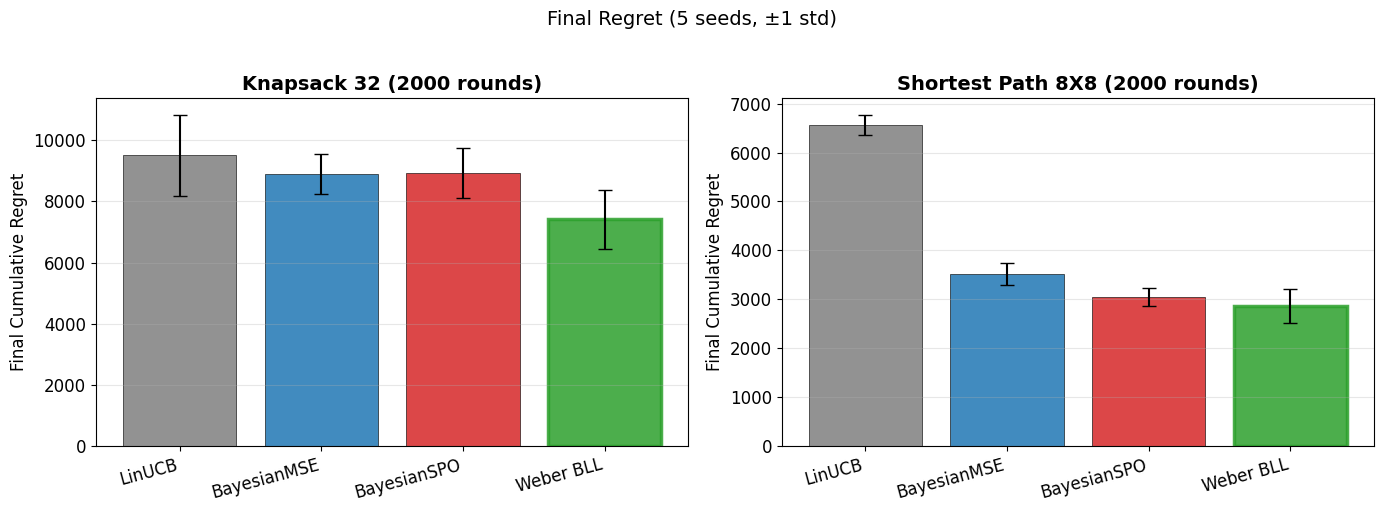

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ds_name in zip(axes, DS_NAMES):
    means, stds, colors, labels = [], [], [], []
    
    for agent_name in AGENT_NAMES:
        trajs = get_trajectories(ds_name, agent_name)
        if len(trajs) == 0:
            continue
        final = trajs[:, -1]
        means.append(np.mean(final))
        stds.append(np.std(final))
        colors.append(COLORS[agent_name])
        labels.append(LABELS[agent_name])
    
    x = np.arange(len(labels))
    bars = ax.bar(x, means, yerr=stds, color=colors, alpha=0.85,
                  capsize=5, edgecolor='k', linewidth=0.5)
    
    best_idx = np.argmin(means)
    bars[best_idx].set_edgecolor('#2ca02c')
    bars[best_idx].set_linewidth(2.5)
    
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=15, ha='right')
    ax.set_ylabel('Final Cumulative Regret')
    title = ds_name.replace('_', ' ').title()
    ax.set_title(f'{title} ({N_ROUNDS} rounds)', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle(f'Final Regret ({N_SEEDS} seeds, ±1 std)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Summary Table

In [7]:
import pandas as pd

rows = []
for ds_name in DS_NAMES:
    for agent_name in AGENT_NAMES:
        trajs = get_trajectories(ds_name, agent_name)
        if len(trajs) == 0:
            continue
        final = trajs[:, -1]
        rows.append({
            'Dataset': ds_name.replace('_', ' ').title(),
            'Agent': LABELS[agent_name],
            'Mean Regret': f'{np.mean(final):.0f}',
            'Std': f'{np.std(final):.0f}',
            'Seeds': len(trajs),
        })

df = pd.DataFrame(rows)
df

,Dataset,Agent,Mean Regret,Std,Seeds
0,Knapsack 32,LinUCB,9507,1318,5
1,Knapsack 32,BayesianMSE,8888,656,5
2,Knapsack 32,BayesianSPO,8920,808,5
3,Knapsack 32,Weber BLL,7420,966,5
4,Shortest Path 8X8,LinUCB,6567,201,5
5,Shortest Path 8X8,BayesianMSE,3516,226,5
6,Shortest Path 8X8,BayesianSPO,3047,193,5
7,Shortest Path 8X8,Weber BLL,2868,350,5


### Regret Improvement vs BayesianSPO

Relative improvement of Weber BLL over BayesianSPO (the main decision-focused baseline).

In [8]:
print("Relative improvement of Weber BLL over baselines:\n")
for ds_name in DS_NAMES:
    weber_final = get_trajectories(ds_name, 'WeberBLL')[:, -1].mean()
    
    print(f"{ds_name.replace('_', ' ').title()}:")
    for agent_name in ['LinUCB', 'BayesianMSE', 'BayesianSPO']:
        baseline_final = get_trajectories(ds_name, agent_name)[:, -1].mean()
        improvement = (baseline_final - weber_final) / baseline_final * 100
        print(f"  vs {LABELS[agent_name]:>15s}: {improvement:+.1f}%  "
              f"({baseline_final:.0f} → {weber_final:.0f})")
    print()

Relative improvement of Weber BLL over baselines:

Knapsack 32:
  vs          LinUCB: +22.0%  (9507 → 7420)
  vs     BayesianMSE: +16.5%  (8888 → 7420)
  vs     BayesianSPO: +16.8%  (8920 → 7420)

Shortest Path 8X8:
  vs          LinUCB: +56.3%  (6567 → 2868)
  vs     BayesianMSE: +18.4%  (3516 → 2868)
  vs     BayesianSPO: +5.9%  (3047 → 2868)

